# Citizen Assist AI — Módulo de Energia para Idosos
Disciplina: Soluções em Energias Renováveis e Sustentáveis (GS 2026.2)

Integrantes:

Nome:            |   RM:

Tiago Muhlmann   |   569569

Wesley Marques   |   573915

Otávio Mancilia  |   570225

Público: idosos (e familiares/cuidadores) que vivem em residência urbana e querem reduzir a conta de luz sem perder conforto nem comprometer equipamentos de saúde.

Necessidade: reduzir o consumo de eletricidade da casa. O chuveiro elétrico é, em geral, o maior consumidor residencial.

Alternativas comparadas (mesma necessidade, mesmo período de 10 anos):

A — Economia: trocar lâmpadas incandescentes por LED e a geladeira antiga por uma com selo Procel A.

B — Renovável:aquecimento solar de água, substituindo parte do consumo do chuveiro elétrico.

Todos os valores marcados como estimados são premissas editáveis e precisam ser conferidos nas fontes da seção de referências antes da entrega.** Nada aqui é resultado garantido.

## 1. Dados e premissas (edite aqui)

In [12]:
#PARÂMETROS GERAIS
# TARIFA: ANEEL (boletim InfoTarifas, 12/jun/2026, via Poder360) projeta tarifa residencial B1
# média de R$ 851/MWh SEM tributos em dez/2026; tributos médios: ICMS 17,3% e PIS/Cofins 5,2%.
# Cálculo (tributos "por dentro", premissa nossa): 0,851 / (1 - 0,173 - 0,052) = ~R$ 1,10/kWh.
# Outras fontes citam R$ 0,85 a R$ 1,00. SUBSTITUA pelo valor da SUA conta de luz.
TARIFA = round(0.851 / (1 - 0.173 - 0.052), 2)   # R$/kWh com tributos - CALCULADO/ESTIMADO

# FATOR_CO2: média anual oficial do SIN em 2023 = 0,0385 tCO2/MWh = 0,0385 kg/kWh (MCTI).
# Em 2025 os valores mensais ficaram entre 0,0215 e 0,0289 kg/kWh (MCTI/SIRENE). Conferir ano mais recente.
FATOR_CO2 = 0.0385

HORIZONTE_ANOS = 10
DIAS_MES = 30
EQUIPAMENTOS = [
    ("Chuveiro elétrico (5500 W)", 5500, 0.5, False),
    ("Lâmpadas incandescentes (6 x 60 W)", 360, 5, False),
    ("TV", 100, 6, False),
    ("Ventilador", 80, 8, False),
    ("Concentrador de oxigênio (exemplo de uso de saúde)", 300, 12, True),
]
GELADEIRA_ANTIGA_KWH_MES = 70

#ALTERNATIVA A: economia
LED_QTD = 6
LED_W_ANTES, LED_W_DEPOIS, LED_HORAS = 60, 9, 5
LED_CUSTO_UNIT = 12.0
GELADEIRA_NOVA_KWH_MES = 35
GELADEIRA_NOVA_CUSTO = 2500.0

#ALTERNATIVA B: renovável (aquecedor solar)
SOLAR_CUSTO = 5000.0
SOLAR_FRACAO = 0.70
SOLAR_MANUT_ANO = 100.0
VIDA_LED_ANOS, VIDA_GELADEIRA_ANOS, VIDA_SOLAR_ANOS = 5, 15, 15

## 2. Cálculos

In [13]:
def kwh_mes(potencia_w, horas_dia):
    # energia (kWh) = potência (kW) x tempo (h)
    return potencia_w / 1000 * horas_dia * DIAS_MES

def consumo_atual():
    linhas = []
    for nome, p, h, saude in EQUIPAMENTOS:
        linhas.append((nome, kwh_mes(p, h), saude))
    linhas.append(("Geladeira antiga", GELADEIRA_ANTIGA_KWH_MES, False))
    return linhas

def medidas():
    # cada medida: nome, alternativa, kWh/mês antes, kWh/mês depois, investimento, vida útil
    led_antes = kwh_mes(LED_QTD * LED_W_ANTES, LED_HORAS)
    led_depois = kwh_mes(LED_QTD * LED_W_DEPOIS, LED_HORAS)
    chuveiro = kwh_mes(5500, 0.5)
    return [
        dict(nome="Trocar lâmpadas por LED", alt="A", antes=led_antes, depois=led_depois,
             custo=LED_QTD * LED_CUSTO_UNIT, manut=0, vida=VIDA_LED_ANOS),
        dict(nome="Trocar geladeira (Procel A)", alt="A", antes=GELADEIRA_ANTIGA_KWH_MES,
             depois=GELADEIRA_NOVA_KWH_MES, custo=GELADEIRA_NOVA_CUSTO, manut=0, vida=VIDA_GELADEIRA_ANOS),
        dict(nome="Aquecedor solar de água", alt="B", antes=chuveiro,
             depois=chuveiro * (1 - SOLAR_FRACAO), custo=SOLAR_CUSTO, manut=SOLAR_MANUT_ANO, vida=VIDA_SOLAR_ANOS),
    ]

def avaliar(m, tarifa=None):
    tarifa = TARIFA if tarifa is None else tarifa
    eco_kwh = m["antes"] - m["depois"]
    eco_mes = eco_kwh * tarifa
    eco_ano = eco_mes * 12 - m["manut"]
    payback = m["custo"] / eco_ano if eco_ano > 0 else None
    # custo líquido em 10 anos, SEM reinvestimento nem juros (simplificação)
    liquido = m["custo"] - eco_ano * HORIZONTE_ANOS
    co2_ano = eco_kwh * 12 * FATOR_CO2
    return dict(eco_kwh_mes=eco_kwh, eco_rs_mes=eco_mes, eco_rs_ano=eco_ano,
                payback_anos=payback, saldo_10anos=-liquido, co2_kg_ano=co2_ano)

def resumo_alternativas(tarifa=None):
    res = {}
    for m in medidas():
        r = avaliar(m, tarifa)
        a = res.setdefault(m["alt"], dict(custo=0, eco_ano=0, co2=0, kwh=0))
        a["custo"] += m["custo"]; a["eco_ano"] += r["eco_rs_ano"]
        a["co2"] += r["co2_kg_ano"]; a["kwh"] += r["eco_kwh_mes"]
    for a in res.values():
        a["payback"] = a["custo"] / a["eco_ano"] if a["eco_ano"] > 0 else None
        a["saldo_10anos"] = a["eco_ano"] * HORIZONTE_ANOS - a["custo"]
    return res

## 3. Resultados e comparação

In [14]:
import pandas as pd

total = sum(k for _, k, _ in consumo_atual())
df = pd.DataFrame(consumo_atual(), columns=["Equipamento", "kWh/mês", "Uso de saúde"])
df["R$/mês"] = (df["kWh/mês"] * TARIFA).round(2)
df["% do total"] = (df["kWh/mês"] / total * 100).round(1)
display(df.round(1))
print(f"Total: {total:.1f} kWh/mês = R$ {total*TARIFA:.2f}/mês (tarifa ESTIMADA R$ {TARIFA}/kWh)")

linhas = []
for m in medidas():
    r = avaliar(m)
    linhas.append([m["alt"], m["nome"], m["custo"], round(r["eco_kwh_mes"],1), round(r["eco_rs_ano"],2),
                   None if r["payback_anos"] is None else round(r["payback_anos"],1),
                   round(r["co2_kg_ano"],1), round(r["saldo_10anos"],2)])
medidas_df = pd.DataFrame(linhas, columns=["Alt","Medida","Investimento R$","Economia kWh/mês",
                                           "Economia R$/ano","Payback (anos)","CO2 evitado kg/ano","Saldo 10 anos R$"])
display(medidas_df)

res = resumo_alternativas()
alt_df = pd.DataFrame(res).T.round(1)
alt_df.index = ["A - Economia (LED + geladeira)", "B - Renovável (aquecedor solar)"]
display(alt_df)

,Equipamento,kWh/mês,Uso de saúde,R$/mês,% do total
0,Chuveiro elétrico (5500 W),82.5,False,90.8,23.5
1,Lâmpadas incandescentes (6 x 60 W),54.0,False,59.4,15.4
2,TV,18.0,False,19.8,5.1
3,Ventilador,19.2,False,21.1,5.5
4,Concentrador de oxigênio (exemplo de uso de sa...,108.0,True,118.8,30.7
5,Geladeira antiga,70.0,False,77.0,19.9


Total: 351.7 kWh/mês = R$ 386.87/mês (tarifa ESTIMADA R$ 1.1/kWh)


,Alt,Medida,Investimento R$,Economia kWh/mês,Economia R$/ano,Payback (anos),CO2 evitado kg/ano,Saldo 10 anos R$
0,A,Trocar lâmpadas por LED,72.0,45.9,605.88,0.1,21.2,5986.8
1,A,Trocar geladeira (Procel A),2500.0,35.0,462.00,5.4,16.2,2120.0
2,B,Aquecedor solar de água,5000.0,57.8,662.30,7.5,26.7,1623.0


,custo,eco_ano,co2,kwh,payback,saldo_10anos
A - Economia (LED + geladeira),2572.0,1067.9,37.4,80.9,2.4,8106.8
B - Renovável (aquecedor solar),5000.0,662.3,26.7,57.8,7.5,1623.0


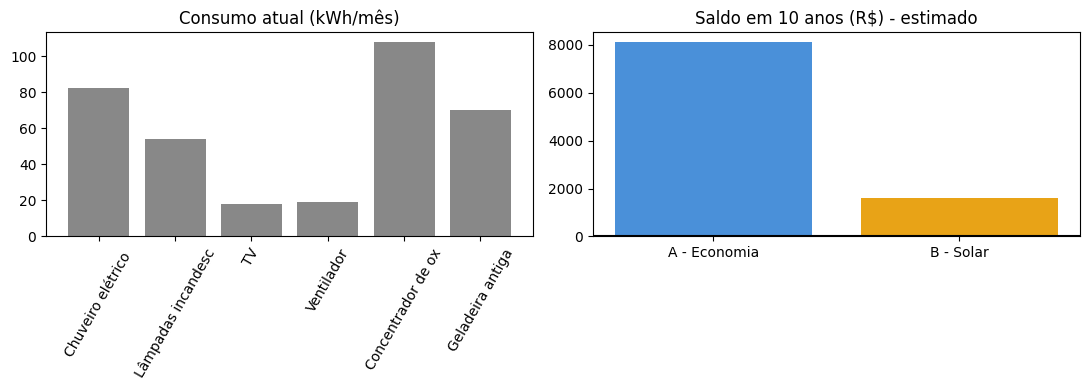

In [15]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(df["Equipamento"].str[:18], df["kWh/mês"], color="#888")
ax[0].set_title("Consumo atual (kWh/mês)"); ax[0].tick_params(axis="x", rotation=60)
ax[1].bar(["A - Economia", "B - Solar"], [res["A"]["saldo_10anos"], res["B"]["saldo_10anos"]], color=["#4a90d9", "#e8a317"])
ax[1].axhline(0, color="black"); ax[1].set_title("Saldo em 10 anos (R$) - estimado")
plt.tight_layout(); plt.show()

## 5. Assistente (menu interativo)

In [16]:
AVISO_SAUDE = ("ATENÇÃO: nunca desligue nem reduza o uso de equipamentos de saúde "
               "(oxigênio, CPAP, cama elétrica etc.) para economizar. Siga sempre a orientação médica.")
AVISO_GERAL = ("Os valores são ESTIMATIVAS e não garantem economia. Este assistente não é um canal oficial "
               "de nenhuma distribuidora ou órgão.")
AVISO_GOLPE = ("CUIDADO COM GOLPES: desconfie de quem promete 'conta de luz zero' ou pede dinheiro adiantado. "
               "Peça pelo menos 3 orçamentos por escrito e não assine nada com pressa. "
               "Peça ajuda a um familiar de confiança.")
REFERENCIAS = [
    "ANEEL - tarifas e Tarifa Social de Energia Elétrica: https://www.gov.br/aneel",
    "Procel/Inmetro - tabelas de consumo e selo de eficiência: https://www.gov.br/inmetro  e  https://www.gov.br/mme (Procel)",
    "CRESESB - irradiação solar: http://www.cresesb.cepel.br",
    "MCTI - fatores de emissão do Sistema Interligado Nacional: https://www.gov.br/mcti",
    "EPE - Balanço Energético Nacional: https://www.epe.gov.br",
]

def ler_opcao(texto, validas):
    while True:
        v = input(texto).strip()
        if v in validas:
            return v
        print(f"Opção inválida. Digite uma destas: {', '.join(validas)}")

def ler_numero(texto, minimo, maximo):
    while True:
        v = input(texto).strip().replace(",", ".")
        try:
            n = float(v)
        except ValueError:
            print("Digite apenas números, por exemplo 0,5."); continue
        if minimo <= n <= maximo:
            return n
        print(f"Digite um valor entre {minimo} e {maximo}.")

def mostrar_consumo():
    print("\nCONSUMO DA CASA DE EXEMPLO (valores estimados)")
    for nome, k, saude in consumo_atual():
        marca = "  [SAÚDE - não reduzir]" if saude else ""
        print(f" - {nome}: {k:.0f} kWh/mês = R$ {k*TARIFA:.2f}{marca}")
    print(f"TOTAL: {total:.0f} kWh/mês = R$ {total*TARIFA:.2f}/mês")
    maior = max((x for x in consumo_atual() if not x[2]), key=lambda x: x[1])
    print(f"Maior consumo (fora saúde): {maior[0]}.")
    print(AVISO_SAUDE)

def mostrar_comparacao(tarifa=None):
    r = resumo_alternativas(tarifa)
    nomes = {"A": "A - Trocar lâmpadas e geladeira (economia)", "B": "B - Aquecedor solar (renovável)"}
    print("\nCOMPARAÇÃO (10 anos, valores estimados)")
    for k in ("A", "B"):
        a = r[k]
        pb = "sem retorno" if a["payback"] is None else f"{a['payback']:.1f} anos"
        print(f"\n{nomes[k]}")
        print(f"  Investimento: R$ {a['custo']:.0f}")
        print(f"  Economia: R$ {a['eco_ano']:.0f} por ano")
        print(f"  Retorno do investimento: {pb}")
        print(f"  CO2 evitado: {a['co2']:.0f} kg por ano")
        print(f"  Saldo em 10 anos: R$ {a['saldo_10anos']:.0f}")
    print("\nDICA: comece pelas lâmpadas LED, que é barato. O solar depende de telhado com sol e espaço.")
    print(AVISO_GERAL)

def meu_perfil():
    global TARIFA
    print("\nVamos ajustar para a sua casa. Nenhum dado pessoal é pedido nem guardado.")
    TARIFA = ler_numero("Quanto custa o kWh na sua conta, em R$ (ex: 0,95)? ", 0.2, 3.0)
    print("Valor da tarifa atualizado para esta consulta.")
    mostrar_comparacao(TARIFA)

def menu():
    while True:
        print("\n===== ASSISTENTE DE ENERGIA =====")
        print("1 - Ver o consumo de uma casa de exemplo")
        print("2 - Comparar as alternativas")
        print("3 - Usar a minha tarifa de luz")
        print("4 - Avisos importantes e cuidado com golpes")
        print("5 - Fontes e referências")
        print("0 - Sair")
        o = ler_opcao("Digite o número da opção: ", ["0","1","2","3","4","5"])
        if o == "0":
            print("Até logo!"); break
        elif o == "1": mostrar_consumo()
        elif o == "2": mostrar_comparacao()
        elif o == "3": meu_perfil()
        elif o == "4": print("\n" + AVISO_SAUDE + "\n" + AVISO_GOLPE + "\n" + AVISO_GERAL)
        elif o == "5":
            print("\nFONTES (confira os dados nelas):")
            for r in REFERENCIAS: print(" -", r)

In [17]:
menu()


===== ASSISTENTE DE ENERGIA =====
1 - Ver o consumo de uma casa de exemplo
2 - Comparar as alternativas
3 - Usar a minha tarifa de luz
4 - Avisos importantes e cuidado com golpes
5 - Fontes e referências
0 - Sair
Digite o número da opção: 0
Até logo!


## 6. Registro dos testes com usuários (preencher com testes REAIS)
Não inventem resultados. Testem com pessoas reais (sem nome ou dados pessoais) e registrem aqui.

In [18]:
import csv, io
registro = [
    # ["Participante", "Perfil", "Situação testada", "Entendeu? (s/n)", "Tempo p/ achar a info (s)", "Comentário", "Ajuste feito"],
    # ["P1", "Idoso, 68 anos", "Opção 2 - comparar", "", "", "", ""],
]
cabecalho = ["Participante","Perfil","Situação testada","Entendeu (s/n)","Tempo (s)","Comentário","Ajuste feito"]
buf = io.StringIO(); w = csv.writer(buf); w.writerow(cabecalho); w.writerows(registro)
open("testes_usuarios.csv", "w", encoding="utf-8").write(buf.getvalue())
print("Arquivo testes_usuarios.csv gerado.")

Arquivo testes_usuarios.csv gerado.
